***DOGS VS CATS IMAGE CLASSIFICATION***

Deep Learning Project using CNN


In [ ]:
# IMPORT REQUIRED LIBRARIES

import os
import random
import shutil
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

print("TensorFlow Version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow Version: 2.20.0
Libraries imported successfully!


In [ ]:
# CHECK GPU AVAILABILITY

gpu = tf.config.list_physical_devices('GPU')

if gpu:
    print("✅ GPU is available!")
    print("GPU:", gpu[0])
else:
    print("⚠️ GPU is not available.")
    print("You can still run the project using CPU.")

✅ GPU is available!
GPU: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


In [ ]:
# DOWNLOAD DOGS VS CATS DATASET

import os
import urllib.request

url = "https://storage.googleapis.com/tensorflow-1-public/course2/cats_and_dogs_filtered.zip"
zip_path = "/content/cats_and_dogs_filtered.zip"

print("📥 Downloading Dogs vs Cats dataset...")
print("Please wait...")

urllib.request.urlretrieve(url, zip_path)

print("\n✅ Dataset downloaded successfully!")

# Check file
if os.path.exists(zip_path):
    size_mb = os.path.getsize(zip_path) / (1024 * 1024)
    print(f"📦 File size: {size_mb:.2f} MB")
else:
    print("❌ Download failed.")

📥 Downloading Dogs vs Cats dataset...
Please wait...

✅ Dataset downloaded successfully!
📦 File size: 65.43 MB


In [ ]:
# EXTRACT DATASET

import zipfile
import os

zip_path = "/content/cats_and_dogs_filtered.zip"
extract_path = "/content/dataset"

print("📂 Extracting dataset...")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("✅ Dataset extracted successfully!")

# Check folders
base_dir = "/content/dataset/cats_and_dogs_filtered"

print("\n📁 Dataset location:")
print(base_dir)

print("\n📂 Available folders:")
print(os.listdir(base_dir))

📂 Extracting dataset...
✅ Dataset extracted successfully!

📁 Dataset location:
/content/dataset/cats_and_dogs_filtered

📂 Available folders:
['train', 'vectorize.py', 'validation']


In [ ]:
#  CHECK DATASET

import os

# Dataset ka main path
base_dir = "/content/dataset/cats_and_dogs_filtered"

# Training aur validation folders
train_dir = os.path.join(base_dir, "train")
validation_dir = os.path.join(base_dir, "validation")

# Count training images
cat_train = len(os.listdir(os.path.join(train_dir, "cats")))
dog_train = len(os.listdir(os.path.join(train_dir, "dogs")))

# Count validation images
cat_val = len(os.listdir(os.path.join(validation_dir, "cats")))
dog_val = len(os.listdir(os.path.join(validation_dir, "dogs")))

print("=" * 55)
print("🐶🐱 DOGS VS CATS DATASET")
print("=" * 55)

print("\n📚 TRAINING DATA")
print("🐱 Cats :", cat_train)
print("🐶 Dogs :", dog_train)

print("\n📚 VALIDATION DATA")
print("🐱 Cats :", cat_val)
print("🐶 Dogs :", dog_val)

print("\n📊 TOTAL AVAILABLE IMAGES")
print("Total :", cat_train + dog_train + cat_val + dog_val)

🐶🐱 DOGS VS CATS DATASET

📚 TRAINING DATA
🐱 Cats : 1000
🐶 Dogs : 1000

📚 VALIDATION DATA
🐱 Cats : 500
🐶 Dogs : 500

📊 TOTAL AVAILABLE IMAGES
Total : 3000


In [ ]:
# — CREATE BALANCED 1600 IMAGE DATASET

import os
import shutil
import random

# New dataset folder
NEW_DATASET = "/content/dogs_cats_1600"

# Agar folder pehle se exist karta hai to delete karo
if os.path.exists(NEW_DATASET):
    shutil.rmtree(NEW_DATASET)

# Cats aur Dogs folders create karo
os.makedirs(os.path.join(NEW_DATASET, "cats"))
os.makedirs(os.path.join(NEW_DATASET, "dogs"))

# Same random selection every time
random.seed(42)

# 800 Cats + 800 Dogs
for animal in ["cats", "dogs"]:

    source_folder = os.path.join(train_dir, animal)

    # Images ki list
    images = os.listdir(source_folder)

    # Randomize
    random.shuffle(images)

    # Sirf 800 images
    selected_images = images[:800]

    # Copy images
    for image_name in selected_images:

        source_path = os.path.join(
            source_folder,
            image_name
        )

        destination_path = os.path.join(
            NEW_DATASET,
            animal,
            image_name
        )

        shutil.copy(source_path, destination_path)

print("=" * 55)
print("✅ BALANCED DATASET CREATED")
print("=" * 55)

cats_count = len(
    os.listdir(os.path.join(NEW_DATASET, "cats"))
)

dogs_count = len(
    os.listdir(os.path.join(NEW_DATASET, "dogs"))
)

print("🐱 Cats :", cats_count)
print("🐶 Dogs :", dogs_count)
print("📊 Total:", cats_count + dogs_count)

✅ BALANCED DATASET CREATED
🐱 Cats : 800
🐶 Dogs : 800
📊 Total: 1600


/tmp/ipykernel_5163/2629714149.py:52: UserWarning: Glyph 128054 (\N{DOG FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128054 (\N{DOG FACE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


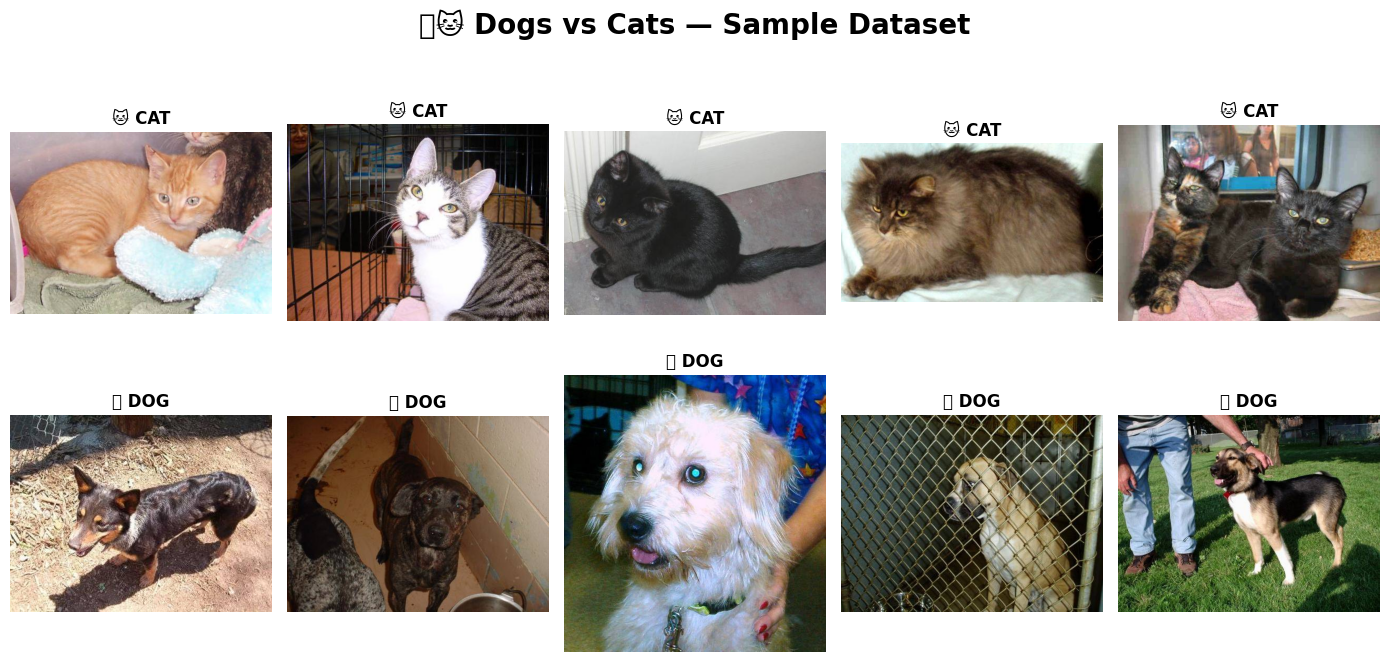

In [ ]:
# — VISUALIZE SAMPLE IMAGES


import matplotlib.pyplot as plt
from PIL import Image
import random
import os

plt.figure(figsize=(14, 7))

classes = ["cats", "dogs"]

for row, animal in enumerate(classes):

    folder = os.path.join(NEW_DATASET, animal)

    images = random.sample(
        os.listdir(folder),
        5
    )

    for col, image_name in enumerate(images):

        image_path = os.path.join(
            folder,
            image_name
        )

        image = Image.open(image_path)

        position = row * 5 + col + 1

        plt.subplot(2, 5, position)

        plt.imshow(image)

        plt.title(
            "🐱 CAT" if animal == "cats"
            else "🐶 DOG",
            fontsize=12,
            fontweight="bold"
        )

        plt.axis("off")

plt.suptitle(
    "🐶🐱 Dogs vs Cats — Sample Dataset",
    fontsize=20,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
# TRAIN / VALIDATION / TEST SPLIT

FINAL_DATASET = "/content/final_dataset"

# Delete old split if it exists
if os.path.exists(FINAL_DATASET):
    shutil.rmtree(FINAL_DATASET)

# Create folders
for split in ["train", "validation", "test"]:

    for animal in ["cats", "dogs"]:

        os.makedirs(
            os.path.join(
                FINAL_DATASET,
                split,
                animal
            )
        )

random.seed(42)

# Split each class separately
for animal in ["cats", "dogs"]:

    source_folder = os.path.join(
        NEW_DATASET,
        animal
    )

    images = os.listdir(source_folder)

    random.shuffle(images)

    # 800 images per class
    train_images = images[:560]
    validation_images = images[560:680]
    test_images = images[680:800]

    # Store splits
    split_data = {
        "train": train_images,
        "validation": validation_images,
        "test": test_images
    }

    # Copy files
    for split, split_images in split_data.items():

        for image_name in split_images:

            source = os.path.join(
                source_folder,
                image_name
            )

            destination = os.path.join(
                FINAL_DATASET,
                split,
                animal,
                image_name
            )

            shutil.copy(source, destination)

print("=" * 55)
print("✅ DATASET SPLIT COMPLETED")
print("=" * 55)

for split in ["train", "validation", "test"]:

    cats = len(
        os.listdir(
            os.path.join(
                FINAL_DATASET,
                split,
                "cats"
            )
        )
    )

    dogs = len(
        os.listdir(
            os.path.join(
                FINAL_DATASET,
                split,
                "dogs"
            )
        )
    )

    print(f"\n{split.upper()}")
    print("🐱 Cats:", cats)
    print("🐶 Dogs:", dogs)
    print("📊 Total:", cats + dogs)

✅ DATASET SPLIT COMPLETED

TRAIN
🐱 Cats: 560
🐶 Dogs: 560
📊 Total: 1120

VALIDATION
🐱 Cats: 120
🐶 Dogs: 120
📊 Total: 240

TEST
🐱 Cats: 120
🐶 Dogs: 120
📊 Total: 240


In [ ]:
#  LOAD IMAGE DATASETS

import tensorflow as tf

# Image size
IMG_SIZE = (150, 150)

# Batch size
BATCH_SIZE = 32

# Training dataset
train_dataset = tf.keras.utils.image_dataset_from_directory(
    os.path.join(FINAL_DATASET, "train"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=42
)

# Validation dataset
validation_dataset = tf.keras.utils.image_dataset_from_directory(
    os.path.join(FINAL_DATASET, "validation"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

# Test dataset
test_dataset = tf.keras.utils.image_dataset_from_directory(
    os.path.join(FINAL_DATASET, "test"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

print("\n✅ DATASETS LOADED")
print("Classes:", train_dataset.class_names)

Found 1120 files belonging to 2 classes.
Found 240 files belonging to 2 classes.
Found 240 files belonging to 2 classes.

✅ DATASETS LOADED
Classes: ['cats', 'dogs']


In [ ]:
# CELL 11 — OPTIMIZE DATA PIPELINE

AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(
    buffer_size=AUTOTUNE
)

validation_dataset = validation_dataset.prefetch(
    buffer_size=AUTOTUNE
)

test_dataset = test_dataset.prefetch(
    buffer_size=AUTOTUNE
)

print("✅ Data pipeline optimized!")

✅ Data pipeline optimized!


In [ ]:
# DATA AUGMENTATION


from tensorflow import keras
from tensorflow.keras import layers

data_augmentation = keras.Sequential([

    layers.RandomFlip(
        "horizontal"
    ),

    layers.RandomRotation(
        0.15
    ),

    layers.RandomZoom(
        0.15
    ),

    layers.RandomContrast(
        0.1
    )
])

print("✅ Data augmentation created!")

✅ Data augmentation created!


/tmp/ipykernel_5163/4271237909.py:37: UserWarning: Glyph 128260 (\N{ANTICLOCKWISE DOWNWARDS AND UPWARDS OPEN CIRCLE ARROWS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128260 (\N{ANTICLOCKWISE DOWNWARDS AND UPWARDS OPEN CIRCLE ARROWS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


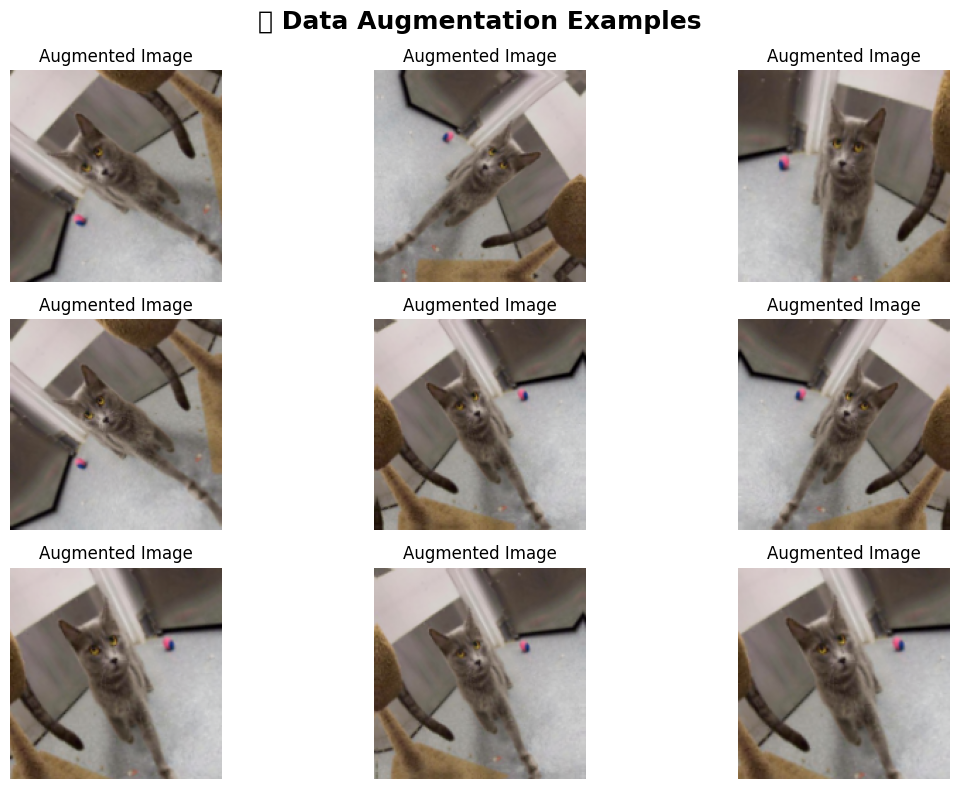

In [ ]:
# VISUALIZE DATA AUGMENTATION

plt.figure(figsize=(12, 8))

for images, labels in train_dataset.take(1):

    original_image = images[0]

    for i in range(9):

        augmented_image = data_augmentation(
            tf.expand_dims(
                original_image,
                0
            ),
            training=True
        )[0]

        plt.subplot(3, 3, i + 1)

        plt.imshow(
            augmented_image.numpy().astype("uint8")
        )

        plt.title(
            "Augmented Image"
        )

        plt.axis("off")

plt.suptitle(
    "🔄 Data Augmentation Examples",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
# BUILD CNN MODEL

from tensorflow.keras.models import Sequential

model = Sequential([

    # Input
    layers.Input(
        shape=(150, 150, 3)
    ),

    # Data augmentation
    data_augmentation,

    # Normalize pixels
    layers.Rescaling(1./255),

    # --------------------------
    # CNN BLOCK 1
    # --------------------------

    layers.Conv2D(
        32,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(),

    # --------------------------
    # CNN BLOCK 2
    # --------------------------

    layers.Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(),

    # --------------------------
    # CNN BLOCK 3
    # --------------------------

    layers.Conv2D(
        128,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(),

    # Reduce overfitting
    layers.Dropout(0.3),

    # Convert feature maps
    # into one-dimensional vector
    layers.Flatten(),

    # Fully connected layer
    layers.Dense(
        128,
        activation="relu"
    ),

    # Reduce overfitting
    layers.Dropout(0.4),

    # Final binary classification
    layers.Dense(
        1,
        activation="sigmoid"
    )
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,481 (18.42 MB)

 Trainable params: 4,828,481 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# COMPILE MODEL

model.compile(

    optimizer="adam",

    loss="binary_crossentropy",

    metrics=[
        "accuracy"
    ]
)

print("✅ CNN model compiled successfully!")

✅ CNN model compiled successfully!


In [ ]:
# CELL 16 — TRAIN CNN MODEL

EPOCHS = 15

print("🚀 Training started...")
print("Please wait until training is completed.")

history = model.fit(

    train_dataset,

    validation_data=validation_dataset,

    epochs=EPOCHS
)

print("\n✅ TRAINING COMPLETED!")

🚀 Training started...
Please wait until training is completed.
Epoch 1/15
35/35 ━━━━━━━━━━━━━━━━━━━━ 8s 53ms/step - accuracy: 0.5089 - loss: 0.7164 - val_accuracy: 0.5000 - val_loss: 0.6923
Epoch 2/15
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - accuracy: 0.5259 - loss: 0.6947 - val_accuracy: 0.5000 - val_loss: 0.6948
Epoch 3/15
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.5223 - loss: 0.6911 - val_accuracy: 0.5667 - val_loss: 0.6821
Epoch 4/15
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.5634 - loss: 0.6854 - val_accuracy: 0.5833 - val_loss: 0.6678
Epoch 5/15
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.5875 - loss: 0.6710 - val_accuracy: 0.6000 - val_loss: 0.6843
Epoch 6/15
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 59ms/step - accuracy: 0.6152 - loss: 0.6665 - val_accuracy: 0.6125 - val_loss: 0.6666
Epoch 7/15
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step - accuracy: 0.6446 - loss: 0.6500 - val_accuracy: 0.6417 - val_loss: 0.6473
Epoch 8/15
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/st

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


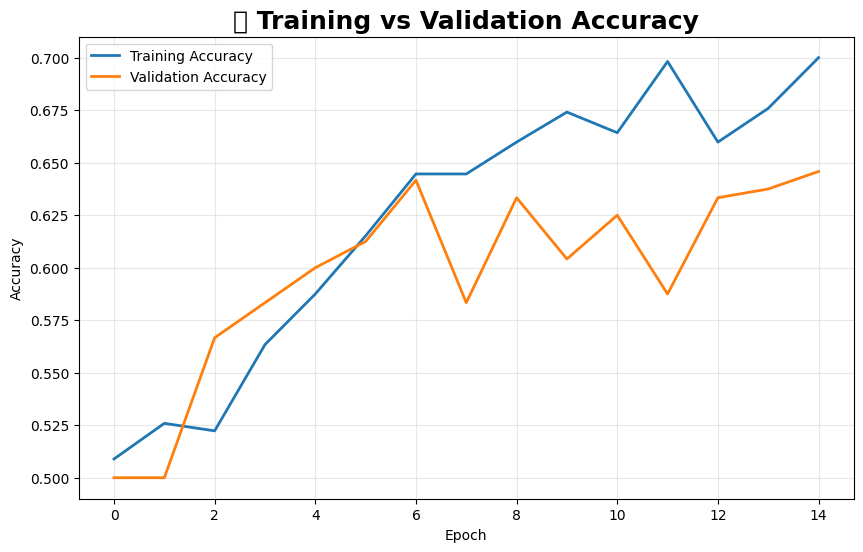

In [ ]:
# TRAINING ACCURACY

plt.figure(figsize=(10, 6))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy",
    linewidth=2
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy",
    linewidth=2
)

plt.title(
    "📈 Training vs Validation Accuracy",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


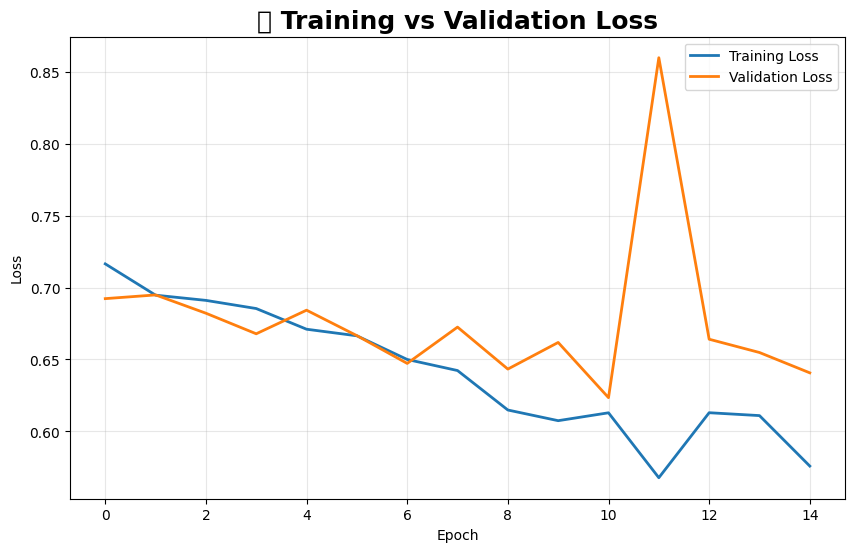

In [ ]:
#  TRAINING LOSS

plt.figure(figsize=(10, 6))

plt.plot(
    history.history["loss"],
    label="Training Loss",
    linewidth=2
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss",
    linewidth=2
)

plt.title(
    "📉 Training vs Validation Loss",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [ ]:
# FINAL TEST EVALUATION

test_loss, test_accuracy = model.evaluate(
    test_dataset
)

print("\n" + "=" * 55)
print("🐶🐱 FINAL MODEL PERFORMANCE")
print("=" * 55)

print(
    f"Test Accuracy : {test_accuracy * 100:.2f}%"
)

print(
    f"Test Loss     : {test_loss:.4f}"
)

print("=" * 55)

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.6917 - loss: 0.6118

🐶🐱 FINAL MODEL PERFORMANCE
Test Accuracy : 69.17%
Test Loss     : 0.6118


In [ ]:
# GENERATE TEST PREDICTIONS

predictions = model.predict(
    test_dataset
)

# Probability → class
predicted_classes = (
    predictions >= 0.5
).astype(int).flatten()

# Actual labels
actual_classes = np.concatenate([
    labels.numpy().flatten()
    for images, labels in test_dataset
])

print("✅ Predictions generated!")

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
✅ Predictions generated!


In [ ]:
#  CLASSIFICATION REPORT

from sklearn.metrics import classification_report

class_names = [
    "Cat",
    "Dog"
]

report = classification_report(
    actual_classes,
    predicted_classes,
    target_names=class_names
)

print("=" * 60)
print("📊 CLASSIFICATION REPORT")
print("=" * 60)
print(report)

📊 CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Cat       0.77      0.55      0.64       120
         Dog       0.65      0.83      0.73       120

    accuracy                           0.69       240
   macro avg       0.71      0.69      0.69       240
weighted avg       0.71      0.69      0.69       240



/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128054 (\N{DOG FACE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


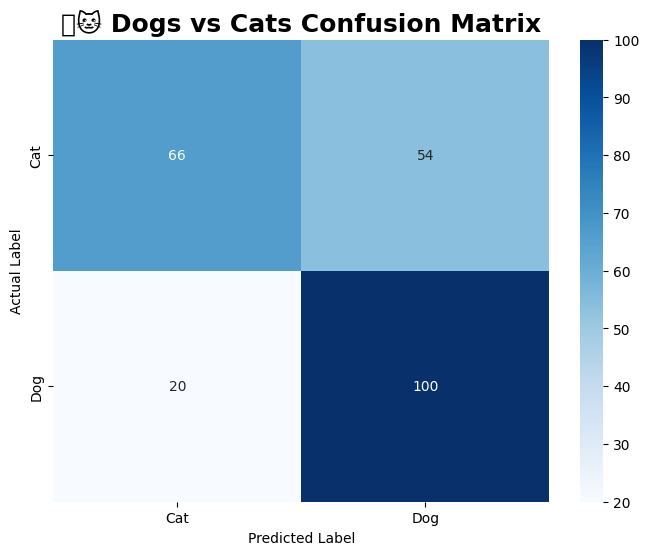

In [ ]:
#  CONFUSION MATRIX

from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(
    actual_classes,
    predicted_classes
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(
    "🐶🐱 Dogs vs Cats Confusion Matrix",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

/tmp/ipykernel_5163/193158161.py:16: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  actual = int(
/tmp/ipykernel_5163/193158161.py:59: UserWarning: Glyph 128269 (\N{LEFT-POINTING MAGNIFYING GLASS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128269 (\N{LEFT-POINTING MAGNIFYING GLASS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


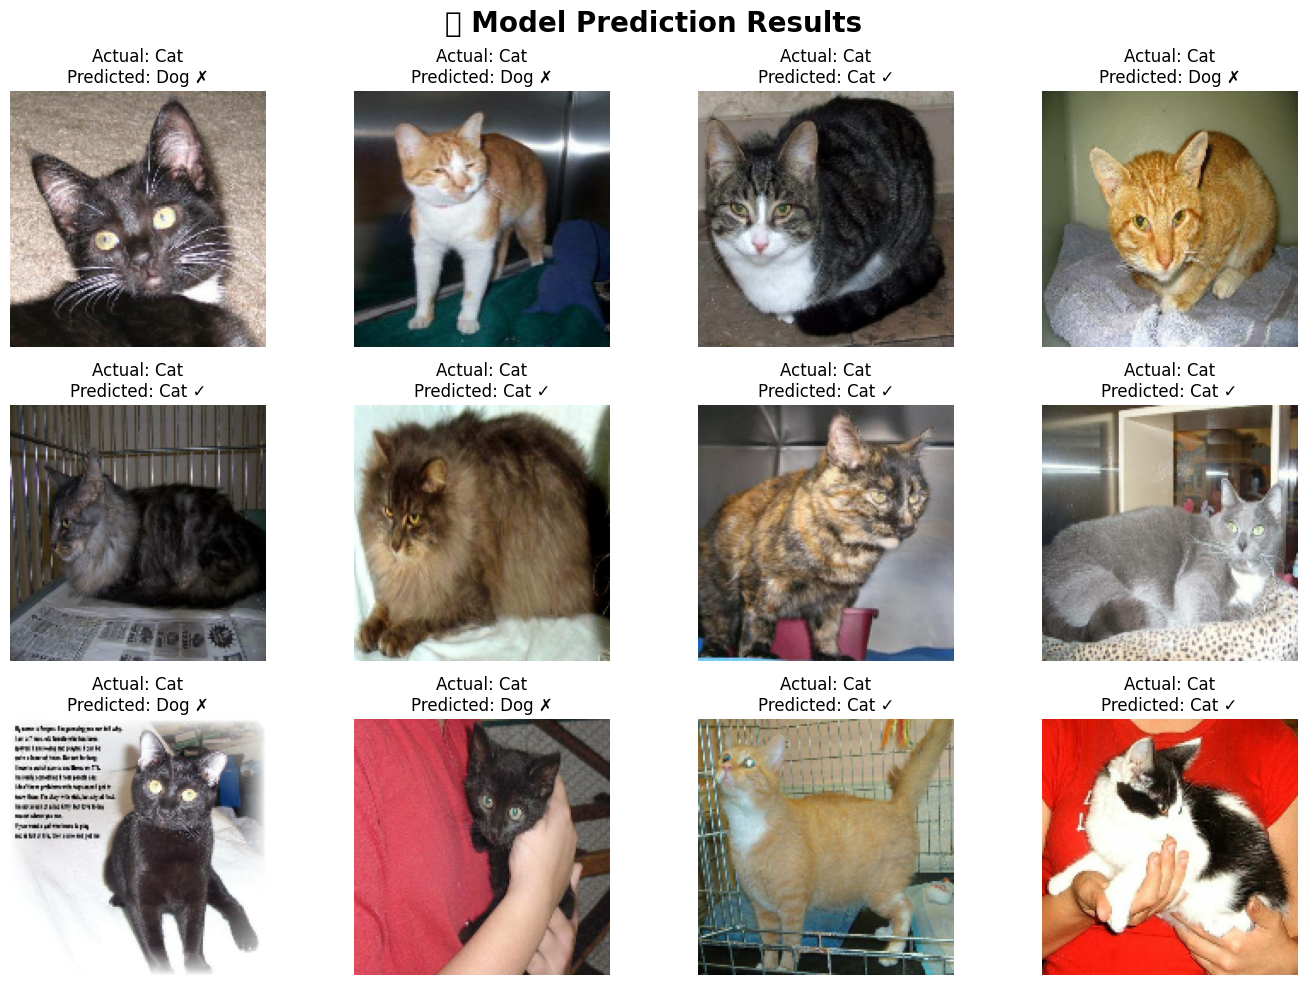

In [ ]:
# VISUALIZE MODEL PREDICTIONS

plt.figure(figsize=(14, 10))

image_counter = 0

for images, labels in test_dataset:

    for i in range(len(images)):

        if image_counter >= 12:
            break

        image = images[i].numpy().astype("uint8")

        actual = int(
            labels[i].numpy()
        )

        predicted = predicted_classes[
            image_counter
        ]

        plt.subplot(3, 4, image_counter + 1)

        plt.imshow(image)

        actual_name = class_names[actual]
        predicted_name = class_names[predicted]

        if actual == predicted:

            title = (
                f"Actual: {actual_name}\n"
                f"Predicted: {predicted_name} ✓"
            )

        else:

            title = (
                f"Actual: {actual_name}\n"
                f"Predicted: {predicted_name} ✗"
            )

        plt.title(title)
        plt.axis("off")

        image_counter += 1

    if image_counter >= 12:
        break

plt.suptitle(
    "🔍 Model Prediction Results",
    fontsize=20,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
# CELL 24 — SAVE TRAINED MODEL

model.save(
    "/content/dogs_vs_cats_cnn.keras"
)

print("✅ Model saved successfully!")
print("\nFile:")
print("dogs_vs_cats_cnn.keras")

✅ Model saved successfully!

File:
dogs_vs_cats_cnn.keras


In [ ]:
# UPLOAD YOUR OWN IMAGE

from google.colab import files

print("📤 Please upload a Dog or Cat image.")

uploaded = files.upload()

uploaded_filename = list(
    uploaded.keys()
)[0]

print("\n✅ Image uploaded:")
print(uploaded_filename)

📤 Please upload a Dog or Cat image.


Saving images (3).jfif to images (3).jfif

✅ Image uploaded:
images (3).jfif


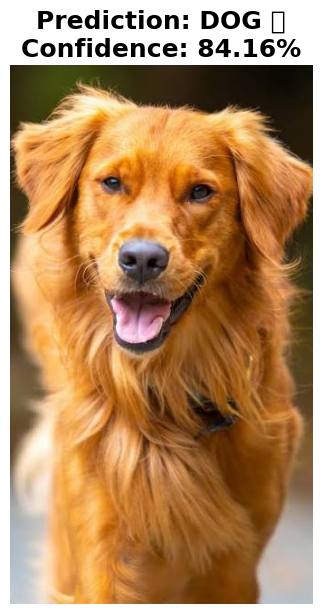

🔮 PREDICTION RESULT
Animal: DOG 🐶
Confidence: 84.16%


In [ ]:
# PREDICT UPLOADED IMAGE

from PIL import Image

# Open image
image = Image.open(
    uploaded_filename
).convert("RGB")

# Resize
image_resized = image.resize(
    (150, 150)
)

# Convert to NumPy
image_array = np.array(
    image_resized
)

# Add batch dimension
image_array = np.expand_dims(
    image_array,
    axis=0
)

# Prediction
prediction = model.predict(
    image_array,
    verbose=0
)[0][0]

# Determine class
if prediction >= 0.5:

    predicted_label = "DOG 🐶"
    confidence = prediction * 100

else:

    predicted_label = "CAT 🐱"
    confidence = (1 - prediction) * 100

# Display image
plt.figure(figsize=(7, 7))

plt.imshow(image)

plt.axis("off")

plt.title(
    f"Prediction: {predicted_label}\n"
    f"Confidence: {confidence:.2f}%",
    fontsize=18,
    fontweight="bold"
)

plt.show()

print("=" * 55)
print("🔮 PREDICTION RESULT")
print("=" * 55)

print("Animal:", predicted_label)
print(f"Confidence: {confidence:.2f}%")

print("=" * 55)

In [ ]:
# FINAL PROJECT SUMMARY

print("=" * 65)
print("🐶🐱 DOGS VS CATS CLASSIFICATION")
print("=" * 65)

print("\n📊 DATASET")
print("Total Images       : 1,600")
print("Cats               : 800")
print("Dogs               : 800")

print("\n📂 DATA SPLIT")
print("Training           : 1,120")
print("Validation         : 240")
print("Testing            : 240")

print("\n🧠 MODEL")
print("Model              : Convolutional Neural Network (CNN)")
print("Image Size         : 150 x 150")
print("Optimizer          : Adam")
print("Loss               : Binary Crossentropy")
print("Epochs             : 15")

print("\n📈 PERFORMANCE")
print(
    f"Test Accuracy      : {test_accuracy * 100:.2f}%"
)
print(
    f"Test Loss          : {test_loss:.4f}"
)

print("\n🎯 TASK")
print("Class 1            : Cat 🐱")
print("Class 2            : Dog 🐶")

print("\n✅ PROJECT COMPLETED!")
print("=" * 65)

🐶🐱 DOGS VS CATS CLASSIFICATION

📊 DATASET
Total Images       : 1,600
Cats               : 800
Dogs               : 800

📂 DATA SPLIT
Training           : 1,120
Validation         : 240
Testing            : 240

🧠 MODEL
Model              : Convolutional Neural Network (CNN)
Image Size         : 150 x 150
Optimizer          : Adam
Loss               : Binary Crossentropy
Epochs             : 15

📈 PERFORMANCE
Test Accuracy      : 69.17%
Test Loss          : 0.6118

🎯 TASK
Class 1            : Cat 🐱
Class 2            : Dog 🐶

✅ PROJECT COMPLETED!
